<div style="text-align: center; font-style: italic; font-size: 18px">Water Resources Management</div>
<div></div>
<div style="text-align: center">Supplementary Information of</div>
<div style="text-align: center; font-weight: bold; font-size: 24px">Data-Driven Leak Localization Modeling for Optimal Sensor Placement</div>

---

Maria Gloria Di Chiano<sup>1*</sup>, Dennis Zanutto<sup>2,3</sup>, Gianfranco Becciu<sup>1</sup>, Dragan Savić<sup>3,4</sup>

<sup>1</sup>D.I.C.A. Politecnico di Milano, 20133 Milano, Italy

<sup>2</sup>D.E.I.B, Politecnico di Milano, 20133, Milano, Italy

<sup>3</sup>KWR Water Research Institute, Nieuwegein, 3430 BB, the Netherlands

<sup>4</sup>Centre for Water Systems, University of Exeter, Exeter, EX4 4QF, United Kingdom


## Content of this File

- Text S7.1
- Text S7.2

## Introduction

This notebook tests the impact of the search area definition method on the data-driven Leak Localization technique across all three Leak Signatrue Matrix (LSM) reconstruction methods on a multi-magnitude leak database. 

In [1]:
# Imports
from wdn_osp_ll.sensor_placement_optimization import load_or_compute
from wdn_osp_ll.visualization import (
    plot_pareto_front_nsensors_msa,
    plot_hypervolume_bar,
    plot_hypervolume_trajectory,
)

## Text S7

## Text S7.1 - Quantile

Using the quantile as search aread definition method should always generate search areas of the same size. Ideally, the same as the nominal resolution, i.e., number of junctions divided by number of sensors. We expect this parameter to converge to inverse of the number of sensors for each sensor configuration when optimised by the algorithm.

In [2]:
boatwright_rel_t_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": None,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "length",
                        "directed": False,
                        "exponent": None,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

boatwright_rel_t_res = load_or_compute(config=boatwright_rel_t_cfg)

In [3]:
alves_rel_t_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": None,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "alves",
                    "args": {
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

alves_rel_t_res = load_or_compute(config=alves_rel_t_cfg)

In [4]:
cluster_rel_t_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": None,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "clustering",
                    "args": {
                        "metric": "length",
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "relative_threshold",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

cluster_rel_t_res = load_or_compute(config=cluster_rel_t_cfg)

In [5]:
boatwright_qt_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": None,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "length",
                        "directed": False,
                        "exponent": None,
                    },
                },
                "search_area_definition_method": {
                    "name": "quantile",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

boatwright_qt_res = load_or_compute(config=boatwright_qt_cfg)

Starting optimisation...
[2026-11-06 15:02:42] generation      0 | best hypervolume: 185.509677 | median: 139.196774
[2026-11-06 15:02:44] generation     10 | best hypervolume: 313.883871 | median: 306.033871
[2026-11-06 15:02:46] generation     20 | best hypervolume: 329.290323 | median: 319.119355
[2026-11-06 15:02:46] generation     30 | best hypervolume: 329.716129 | median: 323.522581
[2026-11-06 15:02:47] generation     40 | best hypervolume: 329.793548 | median: 324.130645
[2026-11-06 15:02:48] generation     50 | best hypervolume: 330.374194 | median: 324.732258
[2026-11-06 15:02:48] generation     60 | best hypervolume: 331.051613 | median: 325.591935
[2026-11-06 15:02:49] generation     70 | best hypervolume: 331.212903 | median: 326.361290
[2026-11-06 15:02:49] generation     80 | best hypervolume: 331.212903 | median: 326.474194
[2026-11-06 15:02:50] generation     90 | best hypervolume: 331.212903 | median: 327.264516
[2026-11-06 15:02:51] generation    100 | best hypervol

In [6]:
alves_qt_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": None,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "alves",
                    "args": {
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "quantile",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

alves_qt_res = load_or_compute(config=alves_qt_cfg)

Starting optimisation...
[2026-11-06 15:02:51] generation      0 | best hypervolume: 162.387097 | median: 110.137097
[2026-11-06 15:02:52] generation     10 | best hypervolume: 296.548387 | median: 284.409677
[2026-11-06 15:02:53] generation     20 | best hypervolume: 306.780645 | median: 300.396774
[2026-11-06 15:02:54] generation     30 | best hypervolume: 309.083871 | median: 302.600000
[2026-11-06 15:02:55] generation     40 | best hypervolume: 309.877419 | median: 304.416129
[2026-11-06 15:02:55] generation     50 | best hypervolume: 309.877419 | median: 304.732258
[2026-11-06 15:02:56] generation     60 | best hypervolume: 309.929032 | median: 304.783871
[2026-11-06 15:02:57] generation     70 | best hypervolume: 309.929032 | median: 305.722581
[2026-11-06 15:02:58] generation     80 | best hypervolume: 309.929032 | median: 305.722581
[2026-11-06 15:02:58] generation     90 | best hypervolume: 309.929032 | median: 305.722581
[2026-11-06 15:02:59] generation    100 | best hypervol

In [7]:
cluster_qt_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": None,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "clustering",
                    "args": {
                        "metric": "length",
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "quantile",
                    "args": {
                        "threshold": None,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

cluster_qt_res = load_or_compute(config=cluster_qt_cfg)

Starting optimisation...
[2026-11-06 15:02:59] generation      0 | best hypervolume: 214.096774 | median: 169.606452
[2026-11-06 15:03:00] generation     10 | best hypervolume: 338.116129 | median: 322.735484
[2026-11-06 15:03:00] generation     20 | best hypervolume: 342.225806 | median: 340.038710
[2026-11-06 15:03:01] generation     30 | best hypervolume: 343.516129 | median: 341.630645
[2026-11-06 15:03:01] generation     40 | best hypervolume: 343.516129 | median: 341.791935
[2026-11-06 15:03:01] generation     50 | best hypervolume: 343.516129 | median: 342.075806
[2026-11-06 15:03:02] generation     60 | best hypervolume: 343.516129 | median: 342.527419
[2026-11-06 15:03:02] generation     70 | best hypervolume: 343.612903 | median: 342.688710
[2026-11-06 15:03:02] generation     80 | best hypervolume: 343.806452 | median: 342.766129
[2026-11-06 15:03:03] generation     90 | best hypervolume: 343.864516 | median: 342.766129
[2026-11-06 15:03:03] generation    100 | best hypervol

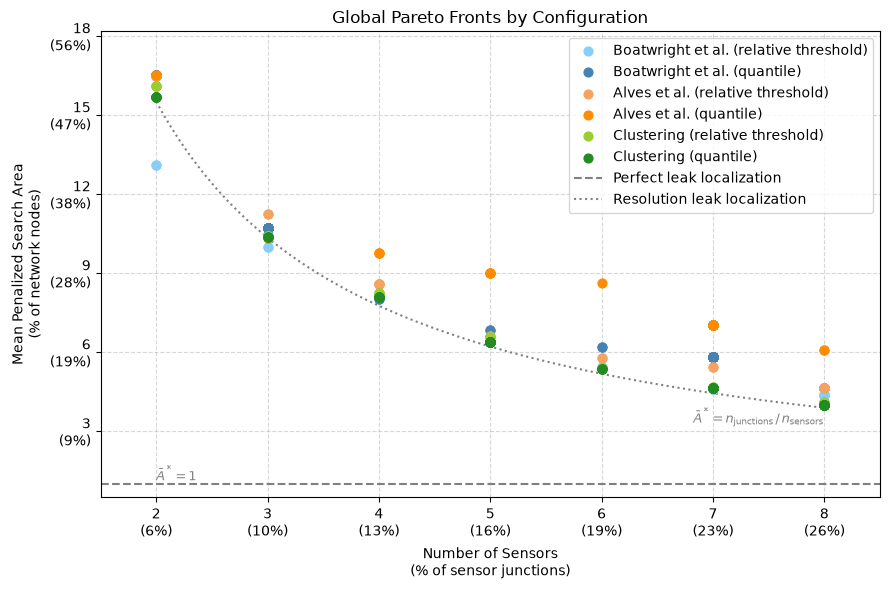

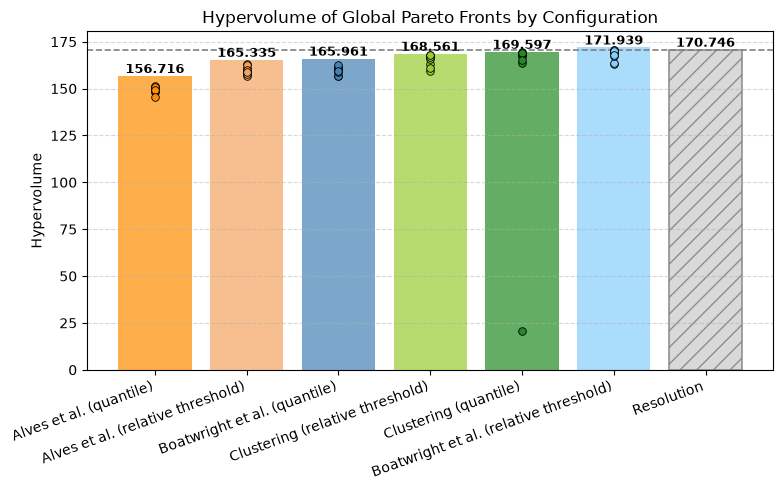

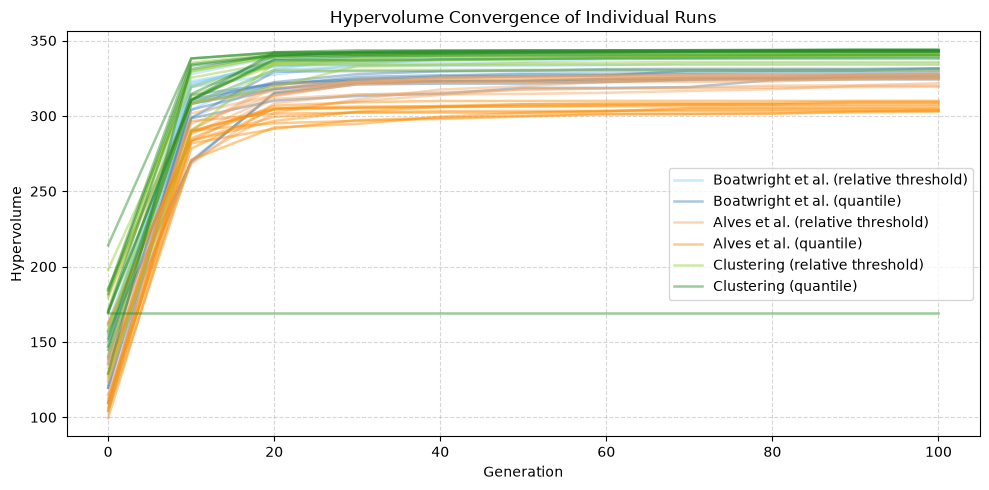

In [8]:
results = [
    boatwright_rel_t_res, boatwright_qt_res,
    alves_rel_t_res, alves_qt_res,
    cluster_rel_t_res, cluster_qt_res,
]
labels = [
    "Boatwright et al. (relative threshold)", "Boatwright et al. (quantile)",
    "Alves et al. (relative threshold)", "Alves et al. (quantile)",
    "Clustering (relative threshold)", "Clustering (quantile)",
]
colors = [
    "lightskyblue", "steelblue",
    "sandybrown", "darkorange",
    "yellowgreen", "forestgreen",
]

fig, ax = plot_pareto_front_nsensors_msa(results, labels, colors)
fig, ax = plot_hypervolume_bar(results, labels, colors)
fig, ax = plot_hypervolume_trajectory(results, labels, colors)

**Results.** Using a relative threshold to define the leak search area outperforms using the quantile. The choice of using the relative threshold on all previous experiments was therefore correct. 

## Text S7.2 - Absolute Threshold

Using an absolute threshold as search aread definition method is effectively like deploying a Leak Detection method alongside the Leak Localization method. As leaks of different magnitudes generate different pressure drops, a single threshold would not be able to capture all leaks.

In [9]:
boatwright_abs_t_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": None,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "boatwright",
                    "args": {
                        "metric": "length",
                        "directed": False,
                        "exponent": None,
                    },
                },
                "search_area_definition_method": {
                    "name": "absolute_threshold",
                    "args": {
                        "threshold": None,
                        "max_threshold": 10,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

boatwright_abs_t_res = load_or_compute(config=boatwright_abs_t_cfg)

Starting optimisation...
[2026-11-06 15:03:04] generation      0 | best hypervolume: 64.848387 | median: 53.819355
[2026-11-06 15:03:04] generation     10 | best hypervolume: 142.880645 | median: 135.083871
[2026-11-06 15:03:05] generation     20 | best hypervolume: 148.987097 | median: 145.866129
[2026-11-06 15:03:05] generation     30 | best hypervolume: 149.748387 | median: 147.856452
[2026-11-06 15:03:06] generation     40 | best hypervolume: 150.351613 | median: 149.583871
[2026-11-06 15:03:06] generation     50 | best hypervolume: 151.054839 | median: 150.374194
[2026-11-06 15:03:07] generation     60 | best hypervolume: 151.590323 | median: 150.472581
[2026-11-06 15:03:07] generation     70 | best hypervolume: 151.745161 | median: 150.548387
[2026-11-06 15:03:08] generation     80 | best hypervolume: 151.816129 | median: 150.580645
[2026-11-06 15:03:08] generation     90 | best hypervolume: 151.900000 | median: 150.627419
[2026-11-06 15:03:09] generation    100 | best hypervolum

In [10]:
alves_abs_t_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": None,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "alves",
                    "args": {
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "absolute_threshold",
                    "args": {
                        "threshold": None,
                        "max_threshold": 10,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

alves_abs_t_res = load_or_compute(config=alves_abs_t_cfg)

Starting optimisation...
[2026-11-06 15:03:09] generation      0 | best hypervolume: 64.554839 | median: 50.511290
[2026-11-06 15:03:10] generation     10 | best hypervolume: 126.164516 | median: 122.211290
[2026-11-06 15:03:11] generation     20 | best hypervolume: 131.841935 | median: 129.243548
[2026-11-06 15:03:11] generation     30 | best hypervolume: 133.632258 | median: 131.612903
[2026-11-06 15:03:12] generation     40 | best hypervolume: 134.164516 | median: 132.375806
[2026-11-06 15:03:13] generation     50 | best hypervolume: 134.538710 | median: 132.554839
[2026-11-06 15:03:13] generation     60 | best hypervolume: 135.122581 | median: 132.835484
[2026-11-06 15:03:14] generation     70 | best hypervolume: 135.251613 | median: 132.900000
[2026-11-06 15:03:14] generation     80 | best hypervolume: 135.303226 | median: 133.322581
[2026-11-06 15:03:15] generation     90 | best hypervolume: 135.306452 | median: 133.527419
[2026-11-06 15:03:16] generation    100 | best hypervolum

In [11]:
cluster_abs_t_cfg = {
    "problem": {
        "leak_analysis": {
            "config": "hyd_analysis/hanoi_base.yaml",
            "emitter_coefficient_filter": None,
            "signature_matrix": "chi_squared",
            "scale_nodes_by_scenario_mean": True,
        },

        "dd_leak_localization": {
            "name": "two_steps",
            "args": {
                "reconstruction_method": {
                    "name": "clustering",
                    "args": {
                        "metric": "length",
                        "directed": False,
                    },
                },
                "search_area_definition_method": {
                    "name": "absolute_threshold",
                    "args": {
                        "threshold": None,
                        "max_threshold": 10,
                    },
                },
            },
        },

        "excluded_junctions": None,
        "n_sensors": None,

        "metrics": [
        ],

        "objectives": [
            "mean_penalized_search_area",
            "n_sensors",
        ],
    },

    "algorithm": {
        "generations": 100,
        "report_every": 10,
        "n_islands": 10,
        "population_size": 100,
    },
}

cluster_abs_t_res = load_or_compute(config=cluster_abs_t_cfg)

Starting optimisation...
[2026-11-06 15:03:16] generation      0 | best hypervolume: 75.251613 | median: 62.629032
[2026-11-06 15:03:16] generation     10 | best hypervolume: 150.383871 | median: 143.956452
[2026-11-06 15:03:16] generation     20 | best hypervolume: 155.435484 | median: 153.746774
[2026-11-06 15:03:17] generation     30 | best hypervolume: 156.838710 | median: 155.275806
[2026-11-06 15:03:17] generation     40 | best hypervolume: 157.206452 | median: 155.706452
[2026-11-06 15:03:17] generation     50 | best hypervolume: 157.335484 | median: 155.774194
[2026-11-06 15:03:17] generation     60 | best hypervolume: 157.654839 | median: 155.995161
[2026-11-06 15:03:18] generation     70 | best hypervolume: 157.809677 | median: 156.087097
[2026-11-06 15:03:18] generation     80 | best hypervolume: 157.812903 | median: 156.122581
[2026-11-06 15:03:18] generation     90 | best hypervolume: 157.854839 | median: 156.188710
[2026-11-06 15:03:18] generation    100 | best hypervolum

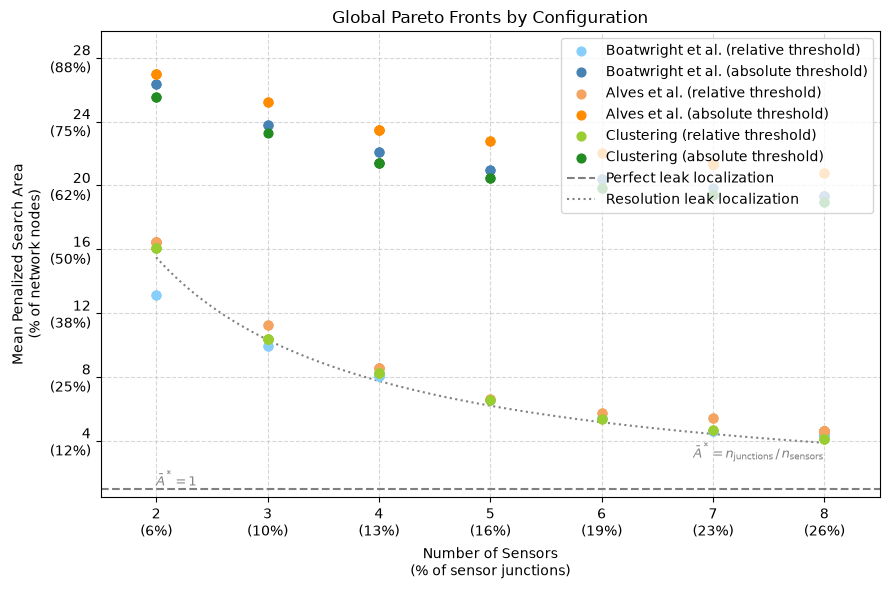

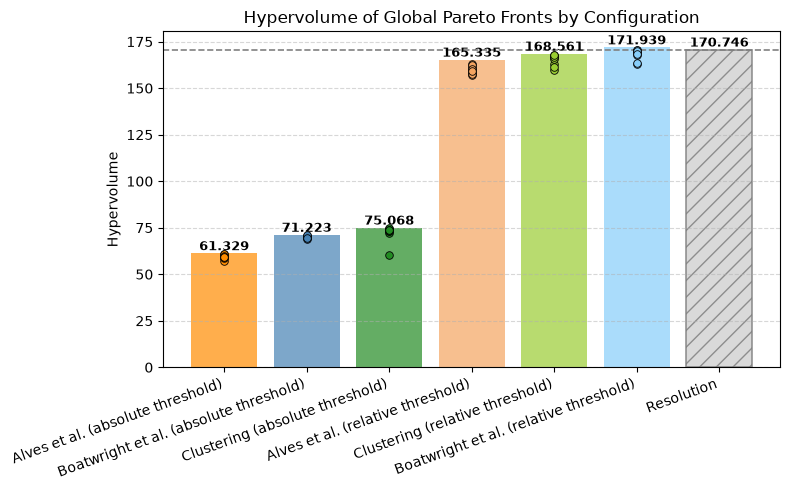

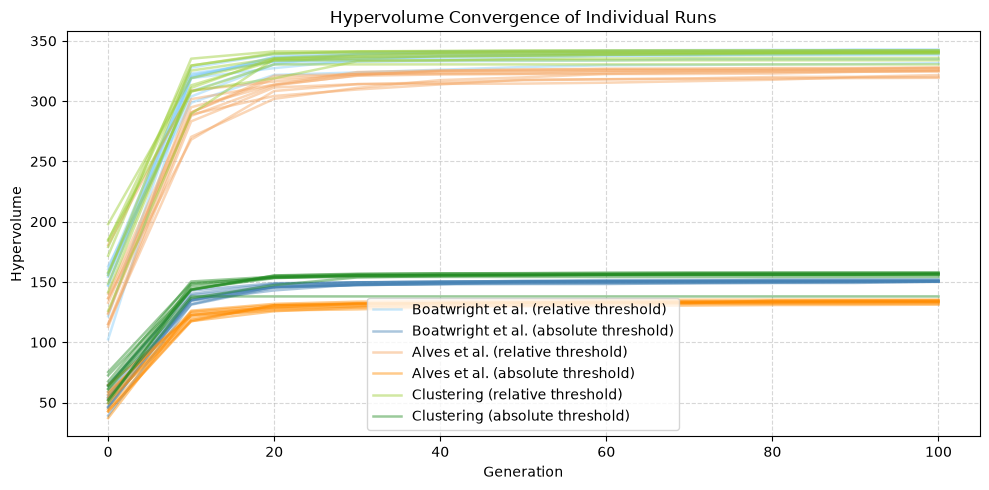

In [12]:
results = [
    boatwright_rel_t_res, boatwright_abs_t_res,
    alves_rel_t_res, alves_abs_t_res,
    cluster_rel_t_res, cluster_abs_t_res,
]
labels = [
    "Boatwright et al. (relative threshold)", "Boatwright et al. (absolute threshold)",
    "Alves et al. (relative threshold)", "Alves et al. (absolute threshold)",
    "Clustering (relative threshold)", "Clustering (absolute threshold)",
]
colors = [
    "lightskyblue", "steelblue",
    "sandybrown", "darkorange",
    "yellowgreen", "forestgreen",
]

fig, ax = plot_pareto_front_nsensors_msa(results, labels, colors)
fig, ax = plot_hypervolume_bar(results, labels, colors)
fig, ax = plot_hypervolume_trajectory(results, labels, colors)

**Results.** Using a relative threshold to define the leak search area outperforms using an absolute one. As hinted at the beginning of this section, using an absolute threshold to determines a leak search area effectively works like embedding the leak detection technique alongised the leak localization. This tasks is much more difficult and using only the relative threshold provides an upper bound in case of a-priori knowledge of the presence of a leak. 